# DBSCAN

DBSCAN uses distances to count neighbors inside ε. If features are on different scales (e.g., YearPublished vs NumOwned_log), distance becomes dominated by the biggest-scale feature, giving us bad clusters. So we standardize features (mean 0, std 1) before DBSCAN. This is consistent with density-based clustering practice because density is defined via neighborhoods in feature space.

For DBSCAN, we should avoid:
- binary category columns (Cat:*) because they create many ties and distort Euclidean distance
- We also avoid rating as an input feature because clustering is unsupervised and we’ll use rating later to interpret clusters

So we’ll start with a compact “behavioral” feature set:
- complexity: GameWeight
- players: MinPlayers, MaxPlayers
- age: ComAgeRec, MfgAgeRec
- popularity: NumOwned_log, NumInterest_log, NumUserRatings_log
- duration: ComMinPlaytime, ComMaxPlaytime
- meta flags: Kickstarted, IsReimplementation (not necessaey but useful)

If DBSCAN struggles (happens in higher dimensions), we can later try a smaller subsetm mainly only 6–8 continuous features

In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

df = pd.read_csv("df_prepared.csv")

print("Shape:", df.shape)
print(df.dtypes.value_counts())

# DBSCAN features (start continuous-heavy & avoid Cat:* for distance)
dbscan_features = [
    "GameWeight",
    "MinPlayers", "MaxPlayers",
    "ComAgeRec", "MfgAgeRec",
    "NumOwned_log", "NumInterest_log", "NumUserRatings_log",
    "ComMinPlaytime", "ComMaxPlaytime",
    "Kickstarted", "IsReimplementation"
]

# ensure columns exist
missing_cols = [c for c in dbscan_features if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing columns in df_prepared.csv: {missing_cols}")

X = df[dbscan_features].copy()

# check cleanliness
print("NaN check in DBSCAN features")
print(X.isna().sum().sort_values(ascending=False).head(20))

# if any NaNs exist we handle them now
if X.isna().any().any():
    # median imputation as a safe fallback for numeric cols
    for col in X.columns:
        if X[col].isna().any():
            X[col] = X[col].fillna(X[col].median())

# 4) scale which is critical for distance-based methods
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nScaled shape:", X_scaled.shape)
print("Scaled mean (first 5 dims):", X_scaled.mean(axis=0)[:5])
print("Scaled std  (first 5 dims):", X_scaled.std(axis=0)[:5])

Shape: (21616, 32)
int64      21
float64    10
object      1
Name: count, dtype: int64
NaN check in DBSCAN features
GameWeight            0
MinPlayers            0
MaxPlayers            0
ComAgeRec             0
MfgAgeRec             0
NumOwned_log          0
NumInterest_log       0
NumUserRatings_log    0
ComMinPlaytime        0
ComMaxPlaytime        0
Kickstarted           0
IsReimplementation    0
dtype: int64

Scaled shape: (21616, 12)
Scaled mean (first 5 dims): [ 5.91680664e-17  1.05187674e-17  9.20392145e-18 -6.31126042e-17
 -1.05187674e-16]
Scaled std  (first 5 dims): [1. 1. 1. 1. 1.]


**no missing values, scaling checked, so that means no feature dominates the Euclidean distance and the density neighborhoods are geometrically meaningful**

## Choosing ε using the k-distance plot
DBSCAN has two key parameters:
- ε (epsilon): neighborhood radius
- MinPts: minimum number of points to form a dense region

From the lecture:
- A good ε separates dense regions (clusters) from sparse regions (noise)
- This is typically done using a k-distance plot, where: k = MinPts − 1, we sort distances to the k-th nearest neighbor, and we look for a clear “elbow” as a sign for optimal ε

This step is mandatory and explicitly recommended in DBSCAN theory

**choosing MinPts: MinPts ≥ d + 1, where d = number of dimensions (general rule of thumb). we have 12 features so we use MinPts = 13 (for now)**

### k-distance plot

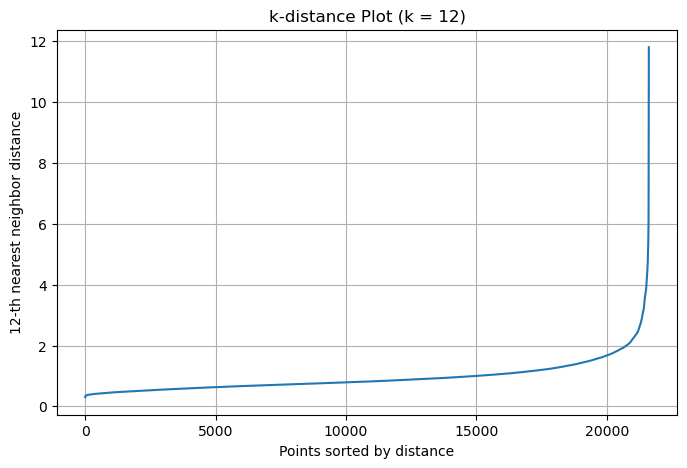

In [2]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

min_pts = 13
k = min_pts - 1

# fit nearest neighbors
nbrs = NearestNeighbors(n_neighbors=k)
nbrs.fit(X_scaled)

# 3) find distances to k-th nearest neighbor
distances, _ = nbrs.kneighbors(X_scaled)

# take the distance to the k-th neighbor
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.xlabel("Points sorted by distance")
plt.ylabel(f"{k}-th nearest neighbor distance")
plt.title(f"k-distance Plot (k = {k})")
plt.grid(True)
plt.show()

the sharp change marks the transition from dense regions (core points inside clusters) to sparse regions / noise / outliers

The curve is relatively flat up to roughly ε 1.8 – 2.0

Choosen paramters:
- ε = 1.9 (reasonable central choice)
- MinPts = 13 (as defined earlier from dimensionality)

Why this is defensible academically:
- ε is derived empirically, not arbitrarily
- The elbow is clearly visible

The ε parameter was selected using the k-distance plot (k = 12), choosing the value immediately before the sharp increase in distances, which indicates the boundary between dense regions and noise.

## Fit DBSCAN

In [3]:
from sklearn.cluster import DBSCAN
import numpy as np
import pandas as pd

# fit DBSCAN
dbscan = DBSCAN(eps=1.9, min_samples=13)
labels_db = dbscan.fit_predict(X_scaled)

# labels
df["Cluster_DBSCAN"] = labels_db

# results
n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise = np.sum(labels_db == -1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print("Noise percentage:", round(n_noise / len(labels_db) * 100, 2), "%")

# cluster size distribution
pd.Series(labels_db).value_counts().sort_index()

Number of clusters: 5
Number of noise points: 510
Noise percentage: 2.36 %


-1      510
 0     2064
 1    15688
 2     2923
 3      110
 4      321
Name: count, dtype: int64

5 clusters: This indicates that the dataset contains five main dense behavioral patterns of board games

Noise percentage: 2.36% acceptable range is usually 2-10%. Indicates ε is not too small (would create excessive noise) and ε is not too large (would absorb noise into clusters)

DBSCAN successfully isolated a small set of atypical or rare games without over-fragmenting the dataset.

Key observations:
- DBSCAN naturally produces imbalanced clusters, which is expected and correct
- Small clusters (e.g., 110, 321) likely represent niche genres
- extreme playtimes
- unusual popularity profiles

Unlike K-Means, DBSCAN does not force these points into large clusters

### Comparison to K-Means
- K-Means: balanced, forced clusters, higher silhouette
- DBSCAN: fewer clusters, natural noise detection, density-aware

## Cluster Profiling

In [4]:
# remove noise
df_core = df[df["Cluster_DBSCAN"] != -1].copy()

# select interpretable features for profiling
profile_features = [
    "YearPublished", "GameWeight",
    "MinPlayers", "MaxPlayers",
    "ComAgeRec", "MfgAgeRec",
    "NumOwned_log", "NumInterest_log",
    "NumUserRatings_log",
    "ComMinPlaytime", "ComMaxPlaytime",
    "Kickstarted", "IsReimplementation"
]

cluster_profile = (
    df_core
    .groupby("Cluster_DBSCAN")[profile_features]
    .mean()
    .round(2)
)

cluster_profile

,YearPublished,GameWeight,MinPlayers,MaxPlayers,ComAgeRec,MfgAgeRec,NumOwned_log,NumInterest_log,NumUserRatings_log,ComMinPlaytime,ComMaxPlaytime,Kickstarted,IsReimplementation
Cluster_DBSCAN,,,,,,,,,,,,,
0,2009.78,2.00,2.01,4.68,9.74,9.61,6.55,4.60,5.70,53.48,66.86,0.0,1.0
1,2004.66,1.93,2.03,4.66,9.83,9.37,5.89,3.86,5.08,57.98,67.80,0.0,0.0
2,2016.29,2.15,1.78,4.69,10.27,11.06,6.28,4.68,5.37,40.83,64.56,1.0,0.0
3,2011.10,1.15,1.96,99.14,9.44,9.65,5.79,3.31,4.79,20.59,29.64,0.0,0.0
4,2017.26,2.34,1.74,4.69,10.34,11.41,6.78,5.31,5.76,45.07,73.49,1.0,1.0


The selected features describe:
- Temporal characteristics (YearPublished)
- Complexity (GameWeight)
- Player structure (MinPlayers, MaxPlayers)
- Age recommendations (ComAgeRec, MfgAgeRec)
- Popularity & engagement (NumOwned_log, NumInterest_log, NumUserRatings_log)
- Playtime (ComMinPlaytime, ComMaxPlaytime)
- Production signals (Kickstarted, IsReimplementation)

This allows us to characterize clusters as distinct “types” of board games emerging from density-based patterns

### Cluster 0: Popular, modern reimplementations
- YearPublished = 2010
- Medium complexity (GameWeight = 2.0)
- Standard player counts (2–5 players)
- Moderate-to-high popularity
- NumOwned_log = 6.55
- NumUserRatings_log = 5.70
- All games are reimplementations (IsReimplementation = 1.0)
- Not Kickstarter-based

This cluster groups established modern games that are frequently reimplemented or revised, suggesting enduring appeal. Their popularity and engagement metrics indicate a strong, stable player base.

### Cluster 1: Classic mainstream board games
- Older publication year (2005)
- Moderate complexity
- Balanced popularity (lower than Cluster 0)
- No Kickstarter involvement
- No reimplementations

This cluster represents traditional, widely accessible board games that achieved popularity through organic diffusion rather than crowdfunding or reimplementation. These games form a dense “core” of the dataset.

### Cluster 2: Kickstarter-driven modern strategy games
- Most recent games (= 2016)
- Higher complexity (GameWeight = 2.15)
- Kickstarter-based (100%)
- Strong engagement and interest
- Not reimplementations

This cluster clearly captures the crowdfunded board game wave: modern, strategy-oriented titles that attract attention and engagement early through Kickstarter campaigns. DBSCAN successfully isolates this trend as a dense region.

### Cluster 3: Very high player-count or party-style games
- Extremely high MaxPlayers (99)
- Low complexity (GameWeight = 1.15)
- Short playtimes
- Lower popularity and engagement
- Not Kickstarter-based, not reimplementations

This cluster isolates party games or mass-participation games, which are structurally different from typical board games. DBSCAN’s ability to separate this group highlights its strength in detecting structural density differences that K-Means would likely smooth over.

### Cluster 4: Highly popular, modern premium games
- Newest games (= 2017)
- Highest complexity (GameWeight = 2.34)
- Highest popularity and interest
- NumOwned_log = 6.78
- NumInterest_log = 5.31
- Kickstarter-based and reimplementations
- Longest playtimes

This cluster represents premium, highly successful modern board games, often crowdfunded and later reimplemented. These games combine complexity, long playtime, and strong community engagement.

## Rating distribution per DBSCAN cluster
DBSCAN is unsupervised, so we need an external variable to validate whether clusters are meaningful. Checking how ratings distribute across DBSCAN clusters tells us whether DBSCAN is capturing quality-related structure.

### rating count per cluster

In [6]:
import pandas as pd

# Count rating per DBSCAN cluster (including noise)
rating_counts_db = pd.crosstab(df["Cluster_DBSCAN"], df["Rating"])
rating_counts_db

Rating,High,Low,Medium
Cluster_DBSCAN,,,
-1,259,95,156
0,641,412,1011
1,2791,6023,6874
2,1130,456,1337
3,12,57,41
4,167,28,126


### rating proportion per cluster

In [7]:
rating_props_db = pd.crosstab(df["Cluster_DBSCAN"], df["Rating"], normalize="index")
rating_props_db.round(3)

Rating,High,Low,Medium
Cluster_DBSCAN,,,
-1,0.508,0.186,0.306
0,0.311,0.200,0.490
1,0.178,0.384,0.438
2,0.387,0.156,0.457
3,0.109,0.518,0.373
4,0.520,0.087,0.393


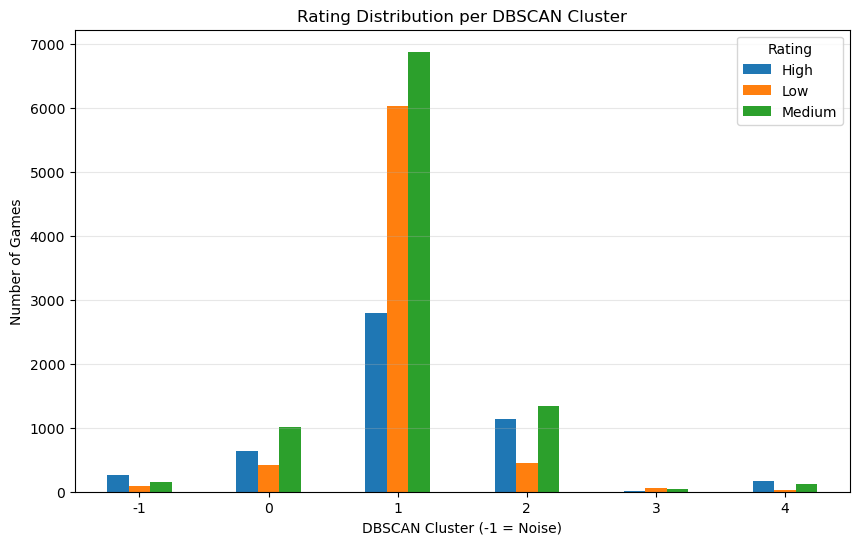

In [8]:
import matplotlib.pyplot as plt

rating_counts_db.plot(kind="bar", figsize=(10,6))
plt.title("Rating Distribution per DBSCAN Cluster")
plt.xlabel("DBSCAN Cluster (-1 = Noise)")
plt.ylabel("Number of Games")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

Counts (no noise):


Rating,High,Low,Medium
Cluster_DBSCAN,,,
0,641,412,1011
1,2791,6023,6874
2,1130,456,1337
3,12,57,41
4,167,28,126



Proportions (no noise):


Rating,High,Low,Medium
Cluster_DBSCAN,,,
0,0.311,0.200,0.490
1,0.178,0.384,0.438
2,0.387,0.156,0.457
3,0.109,0.518,0.373
4,0.520,0.087,0.393


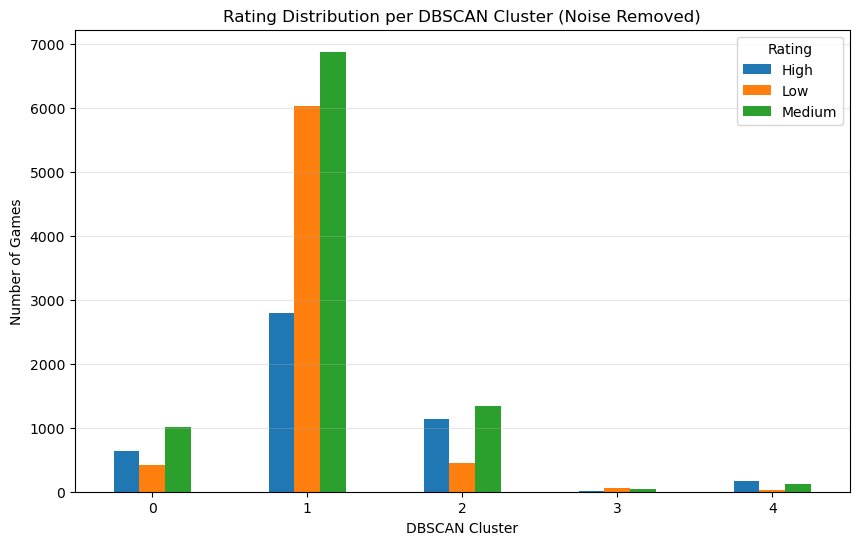

In [9]:
# removing noise
df_core = df[df["Cluster_DBSCAN"] != -1].copy()

rating_counts_core = pd.crosstab(df_core["Cluster_DBSCAN"], df_core["Rating"])
rating_props_core = pd.crosstab(df_core["Cluster_DBSCAN"], df_core["Rating"], normalize="index")

print("Counts (no noise):")
display(rating_counts_core)

print("\nProportions (no noise):")
display(rating_props_core.round(3))

rating_counts_core.plot(kind="bar", figsize=(10,6))
plt.title("Rating Distribution per DBSCAN Cluster (Noise Removed)")
plt.xlabel("DBSCAN Cluster")
plt.ylabel("Number of Games")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

Although DBSCAN is an unsupervised, density-based clustering method, we analyze the distribution of Rating classes within each cluster to evaluate whether the discovered clusters correspond to meaningful quality-related patterns in the data.

Importantly, Rating was not used as a clustering feature, so any alignment between clusters and Rating serves as external validation of the clustering structure.

DBSCAN identifies noise points (label -1), which represent games that do not belong to any dense region in the feature space. Noise was about 2.36% of dataset. Because noise points do not form stable clusters by definition, they are excluded from cluster interpretation in the following analysis.

Insights:
- Cluster 4 stands out as a high-quality cluster, with over half of its games rated “High” and minimal “Low” ratings.
- Clusters 1 and 3 are clearly associated with lower-quality games, particularly Cluster 3, which has a majority of Low-rated games.
- Clusters 0 and 2 represent moderate-quality segments, dominated by Medium-rated games, but with meaningful differences in High/Low balance.

This separation demonstrates that DBSCAN successfully captures latent quality-related structure in the dataset, despite being density-driven and label-agnostic.

## Visual Comparison: K-Means vs DBSCAN
We now compare how K-Means and DBSCAN partition the same dataset

In [11]:
kmeans_labels = pd.read_csv("kmeans_labels.csv")

df = df.merge(kmeans_labels, on="BGGId", how="left")

df[["Cluster_K6", "Cluster_DBSCAN"]].head()

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# SAME feature set as DBSCAN
dbscan_features = [
    "GameWeight",
    "MinPlayers", "MaxPlayers",
    "ComAgeRec", "MfgAgeRec",
    "NumOwned_log", "NumInterest_log", "NumUserRatings_log",
    "ComMinPlaytime", "ComMaxPlaytime",
    "Kickstarted", "IsReimplementation"
]

X = df[dbscan_features].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA 2D projection
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

df["PC1"] = X_pca[:, 0]
df["PC2"] = X_pca[:, 1]

print("Explained variance ratio (PC1, PC2):", pca.explained_variance_ratio_.round(3))

Explained variance ratio (PC1, PC2): [0.278 0.193]


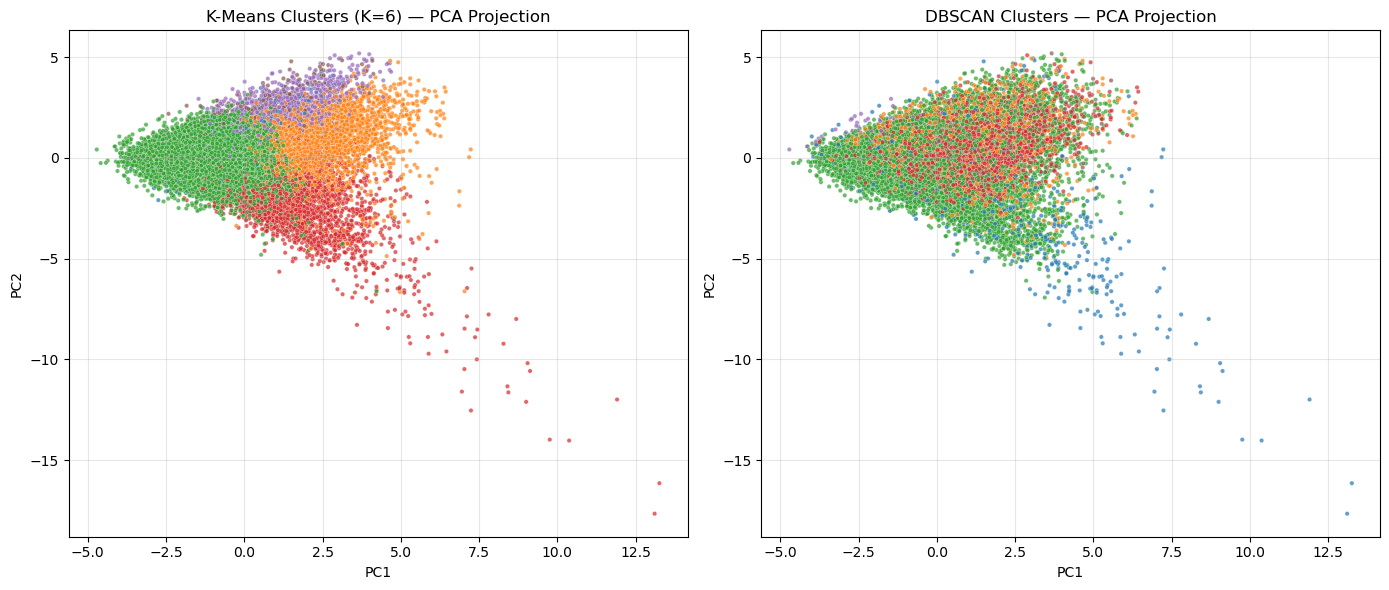

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(
    data=df, x="PC1", y="PC2",
    hue="Cluster_K6",
    palette="tab10",
    s=10, alpha=0.7,
    ax=axes[0], legend=False
)
axes[0].set_title("K-Means Clusters (K=6) — PCA Projection")
axes[0].grid(True, alpha=0.3)

sns.scatterplot(
    data=df, x="PC1", y="PC2",
    hue="Cluster_DBSCAN",
    palette="tab10",
    s=10, alpha=0.7,
    ax=axes[1], legend=False
)
axes[1].set_title("DBSCAN Clusters — PCA Projection")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Visual Comparison: K-Means vs DBSCAN (PCA Projection)

To visually compare the cluster structures produced by K-Means and DBSCAN, we project the standardized feature space onto two principal components using PCA. It is important to stress that PCA is used here only for visualization purposes, not for clustering.

### PCA Explained Variance
The first two principal components explain a total of approximately 47.1%*of the variance in the data:
- **PC1:** 27.8%
- **PC2:** 19.3%

Although this projection does not capture all the variability in the dataset, it is sufficient to provide a meaningful 2D visual comparison of the clustering behaviors.

### K-Means (K = 6)
In the K-Means projection, clusters appear as compact and convex regions with relatively clear boundaries. Every data point is assigned to exactly one cluster, including outliers. This results in:
- Globally structured partitions
- Smooth transitions between clusters
- Some overlap in dense regions where the data distribution is continuous

This behavior is expected, as K-Means minimizes within-cluster variance and assumes roughly spherical cluster shapes.

### DBSCAN
In contrast, the DBSCAN projection (right plot) highlights dense regions of points while isolating sparse areas as noise. Observations include:
- The presence of a distinct noise region (points not belonging to any cluster)
- Irregularly shaped clusters that follow the underlying data density
- Greater robustness to outliers compared to K-Means

DBSCAN does not force every point into a cluster, which allows it to better capture local density variations but can also lead to fewer, less evenly sized clusters

### Comparative Interpretation
The side-by-side comparison emphasizes the fundamental differences between the two algorithms:
- K-Means provides a complete partition of the dataset, producing balanced and interpretable clusters but potentially absorbing noise.
- DBSCAN focuses on density, successfully identifying core structures and filtering out noise, at the cost of less uniform cluster sizes.

Overall, this visualization confirms that while K-Means is effective for global segmentation, DBSCAN offers a complementary perspective by revealing density-based structures and outliers within the same dataset.